# Latent Diffusion and Stable Diffusion

This project implements a class-conditional Latent Diffusion Model (LDM) on the FashionMNIST dataset.

The workflow includes:

1. Loading a pretrained Stable Diffusion VAE.
2. Encoding FashionMNIST images into latent representations.
3. Reconstructing images from VAE latents.
4. Applying forward diffusion in latent space.
5. Implementing a U-Net denoiser with:
   - Sinusoidal time embeddings
   - Class-label embeddings
   - Residual blocks
   - Group normalization
   - SiLU activation
   - Self-attention at 16 × 16 resolution
   - Bottleneck self-attention
   - Skip connections
6. Training with classifier-free guidance.
7. Generating conditional FashionMNIST samples.

## Step 0: Environment Setup

The model is trained using Google Colab with GPU acceleration.

The FashionMNIST images are resized to 128 × 128 pixels. The Stable Diffusion VAE compresses these images into latent tensors with shape:

\[
4 \times 16 \times 16
\]

This resolution allows the U-Net to apply self-attention at the required 16 × 16 latent resolution.

In [3]:
!pip install -q diffusers transformers accelerate torchvision torchmetrics

In [4]:
import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

from diffusers import AutoencoderKL

In [5]:
SEED = 5996

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA L4


In [6]:
# Dataset parameters
IMAGE_SIZE = 128
BATCH_SIZE = 64

# VAE parameters
LATENT_CHANNELS = 4
LATENT_SIZE = 16
LATENT_SCALING_FACTOR = 0.18215

# Diffusion parameters
TIMESTEPS = 1000
BETA_START = 1e-4
BETA_END = 0.02

# U-Net parameters
BASE_CHANNELS = 64
CHANNEL_MULTS = (1, 2, 4)
TIME_EMBED_DIM = BASE_CHANNELS * 4
NUM_CLASSES = 10
NULL_LABEL = 10

# Training parameters
LEARNING_RATE = 2e-5
EPOCHS = 50
LABEL_DROP_PROB = 0.1

# Sampling parameters
GUIDANCE_SCALE = 5.0
NUM_SAMPLES = 64

print("Configuration loaded.")

Configuration loaded.


## Step 1: Load and Preprocess FashionMNIST

FashionMNIST is originally grayscale and has resolution 28 × 28.

The pretrained Stable Diffusion VAE expects three-channel images with values in the range [-1, 1]. Therefore:

- Images are resized to 128 × 128.
- Grayscale images are converted to three channels.
- Pixel values are normalized to [-1, 1].

In [7]:
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 173kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.15MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.1MB/s]

Training samples: 60000
Testing samples: 10000


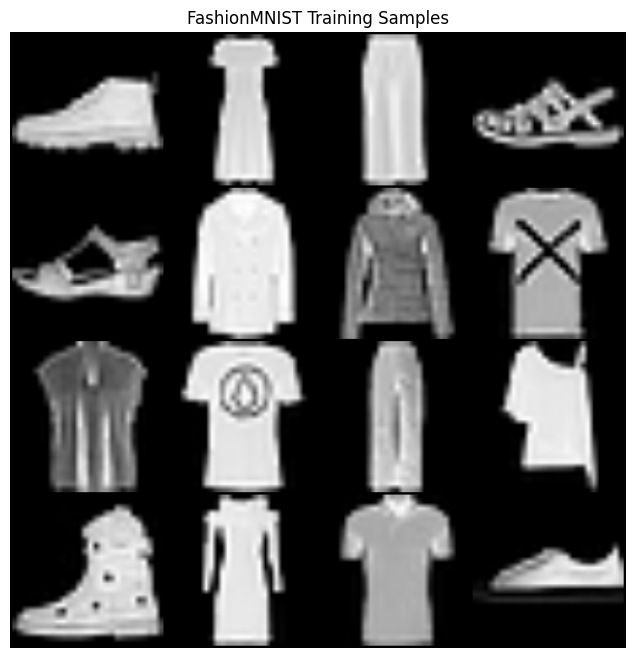

Image shape: torch.Size([64, 3, 128, 128])
Labels: ['Ankle boot', 'Dress', 'Trouser', 'Sandal', 'Sandal', 'Coat', 'Coat', 'T-shirt/top', 'Shirt', 'T-shirt/top', 'Trouser', 'Shirt', 'Ankle boot', 'Dress', 'T-shirt/top', 'Sneaker']


In [8]:
CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

def denormalize(images):
    return (images * 0.5 + 0.5).clamp(0, 1)

images, labels = next(iter(train_loader))

grid = make_grid(
    denormalize(images[:16]),
    nrow=4
)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("FashionMNIST Training Samples")
plt.show()

print("Image shape:", images.shape)
print("Labels:", [CLASS_NAMES[label] for label in labels[:16]])

## Step 2: Load the Pretrained VAE

The pretrained VAE is `stabilityai/sd-vae-ft-mse`.

The VAE performs the following transformation:

\[
x \rightarrow z
\]

where \(x\) is the input image and \(z\) is the latent representation.

The latent representation is multiplied by the standard Stable Diffusion scaling factor:

\[
z_{\text{scaled}} = 0.18215z
\]

During decoding, the latent is divided by the same scaling factor.

In [9]:
vae = AutoencoderKL.from_pretrained(
    "stabilityai/sd-vae-ft-mse"
).to(device)

vae.eval()

for parameter in vae.parameters():
    parameter.requires_grad = False

print("VAE loaded successfully.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

VAE loaded successfully.


In [10]:
@torch.no_grad()
def encode_images(images):
    """
    Encode images into scaled VAE latents.
    Input range: [-1, 1]
    Output shape: [B, 4, 16, 16]
    """
    images = images.to(device)

    posterior = vae.encode(images).latent_dist
    latents = posterior.sample()

    latents = latents * LATENT_SCALING_FACTOR

    return latents


@torch.no_grad()
def decode_latents(latents):
    """
    Decode scaled VAE latents into images.
    Output range: approximately [-1, 1]
    """
    latents = latents / LATENT_SCALING_FACTOR

    reconstructed = vae.decode(latents).sample

    return reconstructed.clamp(-1, 1)

In [11]:
sample_images, sample_labels = next(iter(train_loader))

sample_latents = encode_images(sample_images)

print("Input image shape:", sample_images.shape)
print("Latent shape:", sample_latents.shape)
print("Latent minimum:", sample_latents.min().item())
print("Latent maximum:", sample_latents.max().item())

Input image shape: torch.Size([64, 3, 128, 128])
Latent shape: torch.Size([64, 4, 16, 16])
Latent minimum: -3.7343833446502686
Latent maximum: 4.980642795562744


## Step 3: VAE Reconstruction Evaluation

The scaled latent representations are decoded back into images.

The reconstruction quality is measured using mean squared error:

\[
\text{MSE} = \frac{1}{N}\sum_{i=1}^{N}(x_i-\hat{x}_i)^2
\]

In [12]:
with torch.no_grad():
    reconstructed_images = decode_latents(sample_latents)

reconstruction_mse = F.mse_loss(
    reconstructed_images,
    sample_images.to(device)
).item()

print(f"VAE reconstruction MSE: {reconstruction_mse:.6f}")

VAE reconstruction MSE: 0.000741


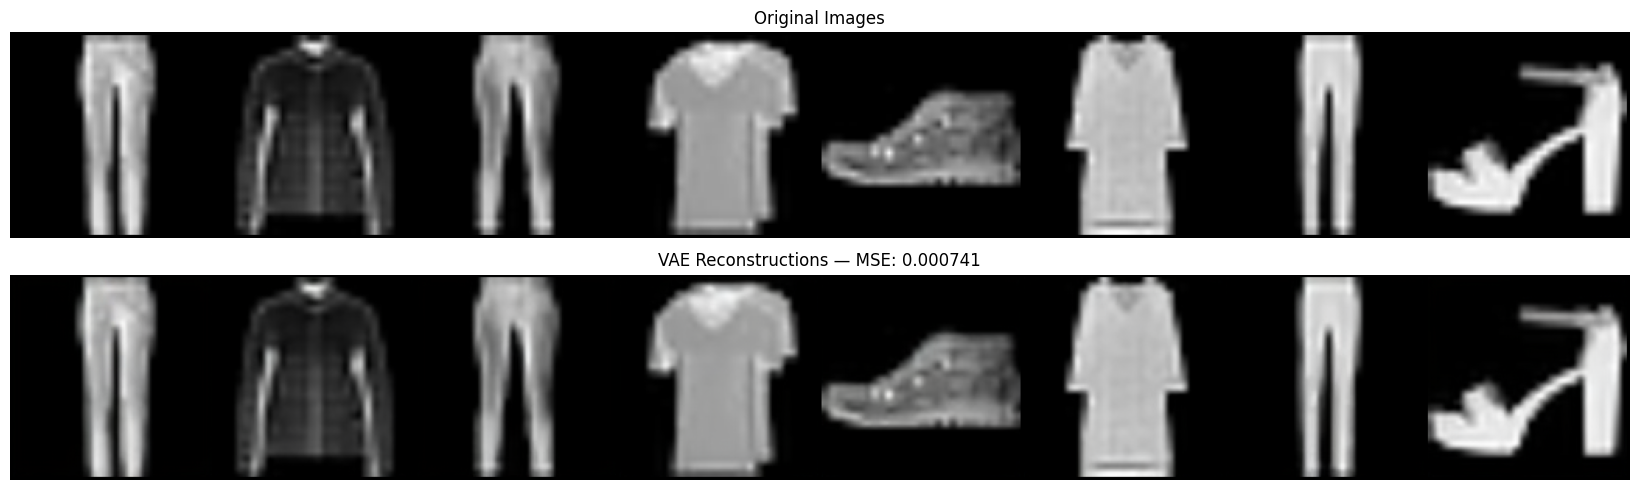

In [13]:
num_display = 8

original_grid = make_grid(
    denormalize(sample_images[:num_display]),
    nrow=num_display
)

reconstruction_grid = make_grid(
    denormalize(reconstructed_images[:num_display].cpu()),
    nrow=num_display
)

plt.figure(figsize=(18, 5))

plt.subplot(2, 1, 1)
plt.imshow(original_grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Original Images")

plt.subplot(2, 1, 2)
plt.imshow(reconstruction_grid.permute(1, 2, 0))
plt.axis("off")
plt.title(f"VAE Reconstructions — MSE: {reconstruction_mse:.6f}")

plt.tight_layout()
plt.show()

## Step 4: Cache Latent Representations

The VAE is frozen, so its latent representations can be computed once and reused during diffusion-model training.

Caching the latents makes training substantially faster because the VAE does not need to run during every diffusion training step.

In [14]:
@torch.no_grad()
def cache_latents(dataset, batch_size=64):
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    all_latents = []
    all_labels = []

    for images, labels in tqdm(loader, desc="Caching latents"):
        latents = encode_images(images)

        all_latents.append(latents.cpu().half())
        all_labels.append(labels.cpu())

    all_latents = torch.cat(all_latents)
    all_labels = torch.cat(all_labels)

    return all_latents, all_labels

In [15]:
train_latents, train_labels = cache_latents(train_dataset)
test_latents, test_labels = cache_latents(test_dataset)

print("Train latent tensor:", train_latents.shape)
print("Test latent tensor:", test_latents.shape)
print("Train latent dtype:", train_latents.dtype)

Caching latents:   0%|          | 0/938 [00:00<?, ?it/s]

Caching latents:   0%|          | 0/157 [00:00<?, ?it/s]

Train latent tensor: torch.Size([60000, 4, 16, 16])
Test latent tensor: torch.Size([10000, 4, 16, 16])
Train latent dtype: torch.float16


In [16]:
latent_train_dataset = TensorDataset(
    train_latents,
    train_labels
)

latent_test_dataset = TensorDataset(
    test_latents,
    test_labels
)

latent_train_loader = DataLoader(
    latent_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

latent_test_loader = DataLoader(
    latent_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Latent training batches:", len(latent_train_loader))
print("Latent testing batches:", len(latent_test_loader))

Latent training batches: 937
Latent testing batches: 157


## Step 5: Forward Diffusion in Latent Space

A linear beta schedule is used:

\[
\beta_t \in [\beta_{\text{start}}, \beta_{\text{end}}]
\]

The forward diffusion equation is:

\[
z_t =
\sqrt{\bar{\alpha}_t}z_0+
\sqrt{1-\bar{\alpha}_t}\epsilon
\]

where:

- \(z_0\) is the clean latent.
- \(z_t\) is the noisy latent.
- \(\epsilon\sim\mathcal{N}(0,I)\).
- \(\bar{\alpha}_t\) is the cumulative product of the diffusion alphas.

In [17]:
betas = torch.linspace(
    BETA_START,
    BETA_END,
    TIMESTEPS,
    device=device
)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

print("Beta schedule created.")
print("First beta:", betas[0].item())
print("Last beta:", betas[-1].item())

Beta schedule created.
First beta: 9.999999747378752e-05
Last beta: 0.019999999552965164


In [18]:
def extract(values, timesteps, x_shape):
    """
    Extract timestep values and reshape them for broadcasting.
    """
    batch_size = timesteps.shape[0]

    out = values.gather(0, timesteps)

    return out.reshape(
        batch_size,
        *((1,) * (len(x_shape) - 1))
    )


def add_noise(latents, timesteps, noise=None):
    """
    Apply forward diffusion to latent representations.
    """
    if noise is None:
        noise = torch.randn_like(latents)

    sqrt_ab = extract(
        sqrt_alpha_bars,
        timesteps,
        latents.shape
    )

    sqrt_one_minus_ab = extract(
        sqrt_one_minus_alpha_bars,
        timesteps,
        latents.shape
    )

    noisy_latents = (
        sqrt_ab * latents
        + sqrt_one_minus_ab * noise
    )

    return noisy_latents, noise

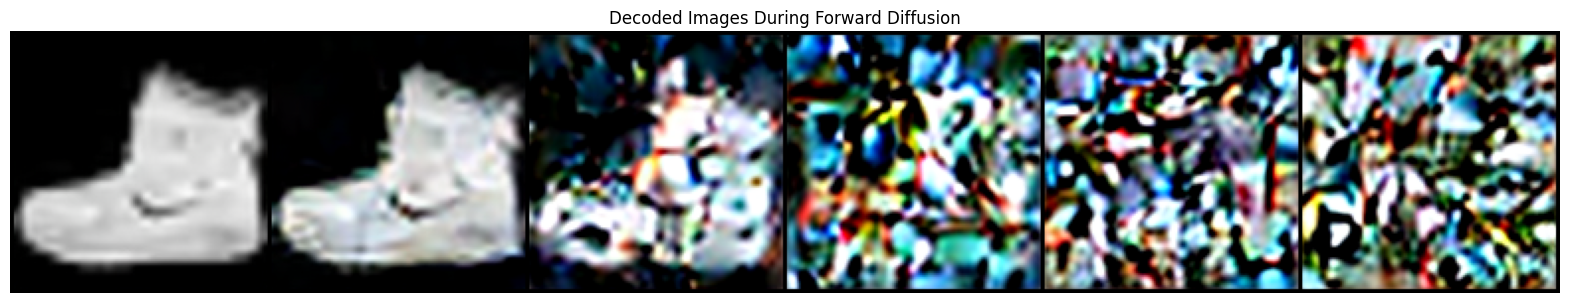

Timesteps: [0, 100, 300, 500, 700, 999]


In [19]:
@torch.no_grad()
def visualize_forward_diffusion():
    latent = train_latents[0:1].float().to(device)

    timestep_values = [0, 100, 300, 500, 700, 999]

    decoded_images = []

    for timestep_value in timestep_values:
        timestep = torch.tensor(
            [timestep_value],
            device=device,
            dtype=torch.long
        )

        noisy_latent, _ = add_noise(latent, timestep)
        decoded = decode_latents(noisy_latent)

        decoded_images.append(decoded.cpu())

    decoded_images = torch.cat(decoded_images, dim=0)

    grid = make_grid(
        denormalize(decoded_images),
        nrow=len(timestep_values)
    )

    plt.figure(figsize=(20, 4))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.title("Decoded Images During Forward Diffusion")
    plt.show()

    print("Timesteps:", timestep_values)

visualize_forward_diffusion()

## Step 6: U-Net Building Blocks

The latent-space U-Net uses:

- Base channels: 64
- Channel multipliers: (1, 2, 4)
- Sinusoidal timestep embeddings
- Label embeddings for 10 classes plus one null class
- Residual blocks
- GroupNorm
- SiLU activation
- Self-attention at 16 × 16
- Self-attention at the bottleneck
- Downsampling and upsampling
- Skip connections

In [20]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()

        self.embedding_dim = embedding_dim

    def forward(self, timesteps):
        half_dim = self.embedding_dim // 2

        exponent = -math.log(10000) / (half_dim - 1)

        frequencies = torch.exp(
            torch.arange(
                half_dim,
                device=timesteps.device
            ) * exponent
        )

        angles = timesteps.float()[:, None] * frequencies[None, :]

        embedding = torch.cat(
            [torch.sin(angles), torch.cos(angles)],
            dim=-1
        )

        return embedding

In [21]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, embedding_dim):
        super().__init__()

        self.norm1 = nn.GroupNorm(
            num_groups=32,
            num_channels=in_channels
        )

        self.activation = nn.SiLU()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.embedding_projection = nn.Linear(
            embedding_dim,
            out_channels
        )

        self.norm2 = nn.GroupNorm(
            num_groups=32,
            num_channels=out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        if in_channels != out_channels:
            self.skip_projection = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )
        else:
            self.skip_projection = nn.Identity()

    def forward(self, x, embedding):
        residual = self.skip_projection(x)

        h = self.norm1(x)
        h = self.activation(h)
        h = self.conv1(h)

        embedding_value = self.embedding_projection(embedding)
        embedding_value = embedding_value[:, :, None, None]

        h = h + embedding_value

        h = self.norm2(h)
        h = self.activation(h)
        h = self.conv2(h)

        return h + residual

In [22]:
class SelfAttentionBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.norm = nn.GroupNorm(
            num_groups=32,
            num_channels=channels
        )

        self.qkv = nn.Conv1d(
            channels,
            channels * 3,
            kernel_size=1
        )

        self.output_projection = nn.Conv1d(
            channels,
            channels,
            kernel_size=1
        )

    def forward(self, x):
        batch_size, channels, height, width = x.shape

        residual = x

        x = self.norm(x)

        x = x.reshape(
            batch_size,
            channels,
            height * width
        )

        qkv = self.qkv(x)

        query, key, value = torch.chunk(
            qkv,
            chunks=3,
            dim=1
        )

        query = query.transpose(1, 2)

        attention_scores = torch.bmm(
            query,
            key
        ) / math.sqrt(channels)

        attention_weights = torch.softmax(
            attention_scores,
            dim=-1
        )

        value = value.transpose(1, 2)

        attended = torch.bmm(
            attention_weights,
            value
        )

        attended = attended.transpose(1, 2)
        attended = self.output_projection(attended)

        attended = attended.reshape(
            batch_size,
            channels,
            height,
            width
        )

        return residual + attended

## Step 7: Conditional Latent U-Net

The model receives:

- A noisy latent \(z_t\)
- A diffusion timestep \(t\)
- A class label \(y\)

The timestep and label embeddings are added together:

\[
e = e_t + e_y
\]

During training, labels are randomly replaced by the null label with probability 0.1. This enables classifier-free guidance during sampling.

In [23]:
class ConditionalLatentUNet(nn.Module):
    def __init__(
        self,
        in_channels=4,
        out_channels=4,
        base_channels=64,
        num_classes=10,
        null_label=10,
        embedding_dim=256
    ):
        super().__init__()

        self.null_label = null_label

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(embedding_dim),
            nn.Linear(embedding_dim, embedding_dim),
            nn.SiLU(),
            nn.Linear(embedding_dim, embedding_dim)
        )

        self.label_embedding = nn.Embedding(
            num_classes + 1,
            embedding_dim
        )

        # Input: 4 x 16 x 16
        self.input_projection = nn.Conv2d(
            in_channels,
            base_channels,
            kernel_size=3,
            padding=1
        )

        # 16 x 16 resolution
        self.block16 = ResidualBlock(
            base_channels,
            base_channels,
            embedding_dim
        )

        self.attention16 = SelfAttentionBlock(
            base_channels
        )

        # Downsample to 8 x 8
        self.down8 = nn.Conv2d(
            base_channels,
            base_channels * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.block8 = ResidualBlock(
            base_channels * 2,
            base_channels * 2,
            embedding_dim
        )

        # Downsample to 4 x 4
        self.down4 = nn.Conv2d(
            base_channels * 2,
            base_channels * 4,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.block4 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            embedding_dim
        )

        # Bottleneck
        self.mid_block1 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            embedding_dim
        )

        self.mid_attention = SelfAttentionBlock(
            base_channels * 4
        )

        self.mid_block2 = ResidualBlock(
            base_channels * 4,
            base_channels * 4,
            embedding_dim
        )

        # Upsample 4 x 4 to 8 x 8
        self.up8 = nn.ConvTranspose2d(
            base_channels * 4,
            base_channels * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up_block8 = ResidualBlock(
            base_channels * 4,
            base_channels * 2,
            embedding_dim
        )

        # Upsample 8 x 8 to 16 x 16
        self.up16 = nn.ConvTranspose2d(
            base_channels * 2,
            base_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.up_block16 = ResidualBlock(
            base_channels * 2,
            base_channels,
            embedding_dim
        )

        self.output_norm = nn.GroupNorm(
            num_groups=32,
            num_channels=base_channels
        )

        self.output_activation = nn.SiLU()

        self.output_projection = nn.Conv2d(
            base_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

    def forward(self, x, timesteps, labels):
        time_embedding = self.time_embedding(timesteps)

        label_embedding = self.label_embedding(labels)

        combined_embedding = (
            time_embedding + label_embedding
        )

        x = self.input_projection(x)

        skip16 = self.block16(
            x,
            combined_embedding
        )

        skip16 = self.attention16(skip16)

        x = self.down8(skip16)

        skip8 = self.block8(
            x,
            combined_embedding
        )

        x = self.down4(skip8)

        x = self.block4(
            x,
            combined_embedding
        )

        x = self.mid_block1(
            x,
            combined_embedding
        )

        x = self.mid_attention(x)

        x = self.mid_block2(
            x,
            combined_embedding
        )

        x = self.up8(x)

        x = torch.cat(
            [x, skip8],
            dim=1
        )

        x = self.up_block8(
            x,
            combined_embedding
        )

        x = self.up16(x)

        x = torch.cat(
            [x, skip16],
            dim=1
        )

        x = self.up_block16(
            x,
            combined_embedding
        )

        x = self.output_norm(x)
        x = self.output_activation(x)
        x = self.output_projection(x)

        return x

In [24]:
model = ConditionalLatentUNet(
    in_channels=LATENT_CHANNELS,
    out_channels=LATENT_CHANNELS,
    base_channels=BASE_CHANNELS,
    num_classes=NUM_CLASSES,
    null_label=NULL_LABEL,
    embedding_dim=TIME_EMBED_DIM
).to(device)

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Trainable parameters: {parameter_count:,}")

Trainable parameters: 6,536,004


In [25]:
test_latents_batch, test_labels_batch = next(
    iter(latent_train_loader)
)

test_latents_batch = test_latents_batch.float().to(device)
test_labels_batch = test_labels_batch.to(device)

test_timesteps = torch.randint(
    0,
    TIMESTEPS,
    (test_latents_batch.shape[0],),
    device=device
)

with torch.no_grad():
    test_output = model(
        test_latents_batch,
        test_timesteps,
        test_labels_batch
    )

print("Input shape:", test_latents_batch.shape)
print("Output shape:", test_output.shape)

Input shape: torch.Size([64, 4, 16, 16])
Output shape: torch.Size([64, 4, 16, 16])


## Step 8: Classifier-Free Guidance Label Dropping

During training, 10% of labels are replaced with the null label.

The null label is represented by index 10 because FashionMNIST contains classes 0 through 9.

In [26]:
def apply_classifier_free_label_dropout(
    labels,
    drop_probability=LABEL_DROP_PROB
):
    random_values = torch.rand(
        labels.shape,
        device=labels.device
    )

    dropped_labels = torch.where(
        random_values < drop_probability,
        torch.full_like(labels, NULL_LABEL),
        labels
    )

    return dropped_labels

## Step 9: Train the Latent Diffusion U-Net

The U-Net is trained to predict the noise added to clean latent representations.

The training objective is:

\[
\mathcal{L}
=
\mathbb{E}_{z_0,t,\epsilon}
\left[
\left\|
\epsilon-\epsilon_\theta(z_t,t,y)
\right\|^2
\right]
\]

In [27]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
    weight_decay=1e-4
)

checkpoint_dir = "./checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

loss_history = []

In [28]:
def train_one_epoch(model, loader, optimizer):
    model.train()

    running_loss = 0.0

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for clean_latents, labels in progress_bar:
        clean_latents = clean_latents.float().to(device)
        labels = labels.to(device)

        batch_size = clean_latents.shape[0]

        timesteps = torch.randint(
            0,
            TIMESTEPS,
            (batch_size,),
            device=device
        )

        noisy_latents, true_noise = add_noise(
            clean_latents,
            timesteps
        )

        training_labels = apply_classifier_free_label_dropout(
            labels
        )

        predicted_noise = model(
            noisy_latents,
            timesteps,
            training_labels
        )

        loss = F.mse_loss(
            predicted_noise,
            true_noise
        )

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.5f}"
        )

    return running_loss / len(loader)

In [29]:
for epoch in range(EPOCHS):
    epoch_loss = train_one_epoch(
        model,
        latent_train_loader,
        optimizer
    )

    loss_history.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Loss: {epoch_loss:.6f}"
    )

    checkpoint_path = os.path.join(
        checkpoint_dir,
        f"latent_diffusion_epoch_{epoch + 1}.pt"
    )

    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "loss": epoch_loss,
            "loss_history": loss_history
        },
        checkpoint_path
    )

Training:   0%|          | 0/937 [00:00<?, ?it/s]

Epoch [1/50] Loss: 0.313054


Training:   0%|          | 0/937 [00:00<?, ?it/s]

Epoch [2/50] Loss: 0.158581


Training:   0%|          | 0/937 [00:00<?, ?it/s]

Epoch [3/50] Loss: 0.136377


... (90 outputs left out)

Training:   0%|          | 0/937 [00:00<?, ?it/s]

Epoch [49/50] Loss: 0.094470


Training:   0%|          | 0/937 [00:00<?, ?it/s]

Epoch [50/50] Loss: 0.094284


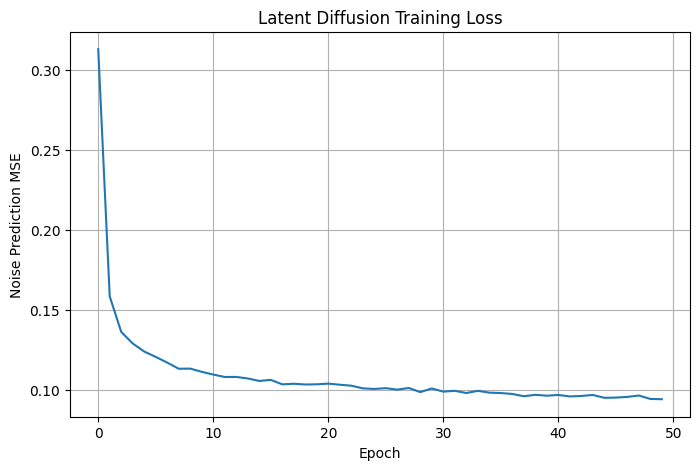

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Noise Prediction MSE")
plt.title("Latent Diffusion Training Loss")
plt.grid(True)
plt.show()

## Step 10: Classifier-Free Guidance Sampling

During sampling, the model produces two predictions:

1. An unconditional prediction using the null label.
2. A conditional prediction using the desired class label.

The predictions are combined using:

\[
\epsilon_{\text{guided}}
=
\epsilon_{\text{unconditional}}
+
s
\left(
\epsilon_{\text{conditional}}
-
\epsilon_{\text{unconditional}}
\right)
\]

where \(s\) is the guidance scale.

In [31]:
@torch.no_grad()
def predict_guided_noise(
    model,
    noisy_latents,
    timesteps,
    labels,
    guidance_scale=GUIDANCE_SCALE
):
    unconditional_labels = torch.full_like(
        labels,
        NULL_LABEL
    )

    conditional_noise = model(
        noisy_latents,
        timesteps,
        labels
    )

    unconditional_noise = model(
        noisy_latents,
        timesteps,
        unconditional_labels
    )

    guided_noise = (
        unconditional_noise
        + guidance_scale
        * (conditional_noise - unconditional_noise)
    )

    return guided_noise

In [32]:
@torch.no_grad()
def sample_latents(
    model,
    labels,
    guidance_scale=GUIDANCE_SCALE
):
    model.eval()

    batch_size = labels.shape[0]

    latents = torch.randn(
        batch_size,
        LATENT_CHANNELS,
        LATENT_SIZE,
        LATENT_SIZE,
        device=device
    )

    for timestep_value in tqdm(
        reversed(range(TIMESTEPS)),
        total=TIMESTEPS,
        desc="Sampling"
    ):
        timesteps = torch.full(
            (batch_size,),
            timestep_value,
            device=device,
            dtype=torch.long
        )

        predicted_noise = predict_guided_noise(
            model,
            latents,
            timesteps,
            labels,
            guidance_scale
        )

        alpha_t = alphas[timestep_value]
        alpha_bar_t = alpha_bars[timestep_value]
        beta_t = betas[timestep_value]

        alpha_t = alpha_t.reshape(1, 1, 1, 1)
        alpha_bar_t = alpha_bar_t.reshape(1, 1, 1, 1)
        beta_t = beta_t.reshape(1, 1, 1, 1)

        posterior_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            latents
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * predicted_noise
        )

        if timestep_value > 0:
            random_noise = torch.randn_like(latents)

            latents = (
                posterior_mean
                + torch.sqrt(beta_t) * random_noise
            )
        else:
            latents = posterior_mean

    return latents


## Step 11: Generate a 64-Image Conditional Sample Grid

The requested 64-image sample grid uses FashionMNIST class labels 0 through 9 repeated until 64 labels are created.

In [33]:
sample_labels = torch.arange(
    NUM_SAMPLES,
    device=device
) % NUM_CLASSES

print("Sampling labels:", sample_labels.cpu().tolist())

Sampling labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3]


In [34]:
generated_latents = sample_latents(
    model,
    sample_labels,
    guidance_scale=GUIDANCE_SCALE
)

generated_images = decode_latents(
    generated_latents
).cpu()

print("Generated latent shape:", generated_latents.shape)
print("Generated image shape:", generated_images.shape)

Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

Generated latent shape: torch.Size([64, 4, 16, 16])
Generated image shape: torch.Size([64, 3, 128, 128])


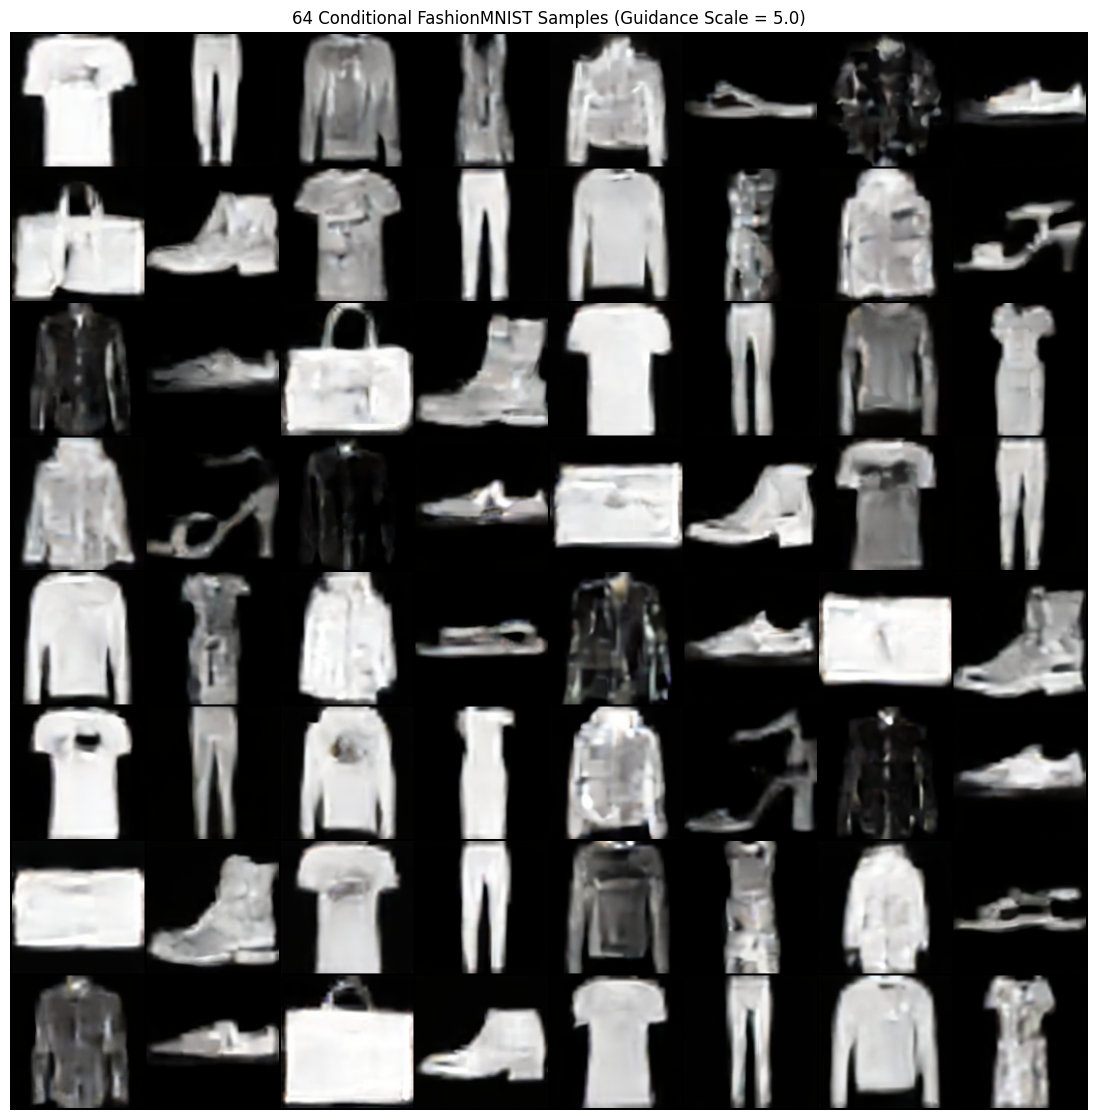

In [35]:
generated_grid = make_grid(
    denormalize(generated_images),
    nrow=8,
    padding=2
)

plt.figure(figsize=(14, 14))
plt.imshow(generated_grid.permute(1, 2, 0))
plt.axis("off")
plt.title(
    f"64 Conditional FashionMNIST Samples "
    f"(Guidance Scale = {GUIDANCE_SCALE})"
)
plt.show()

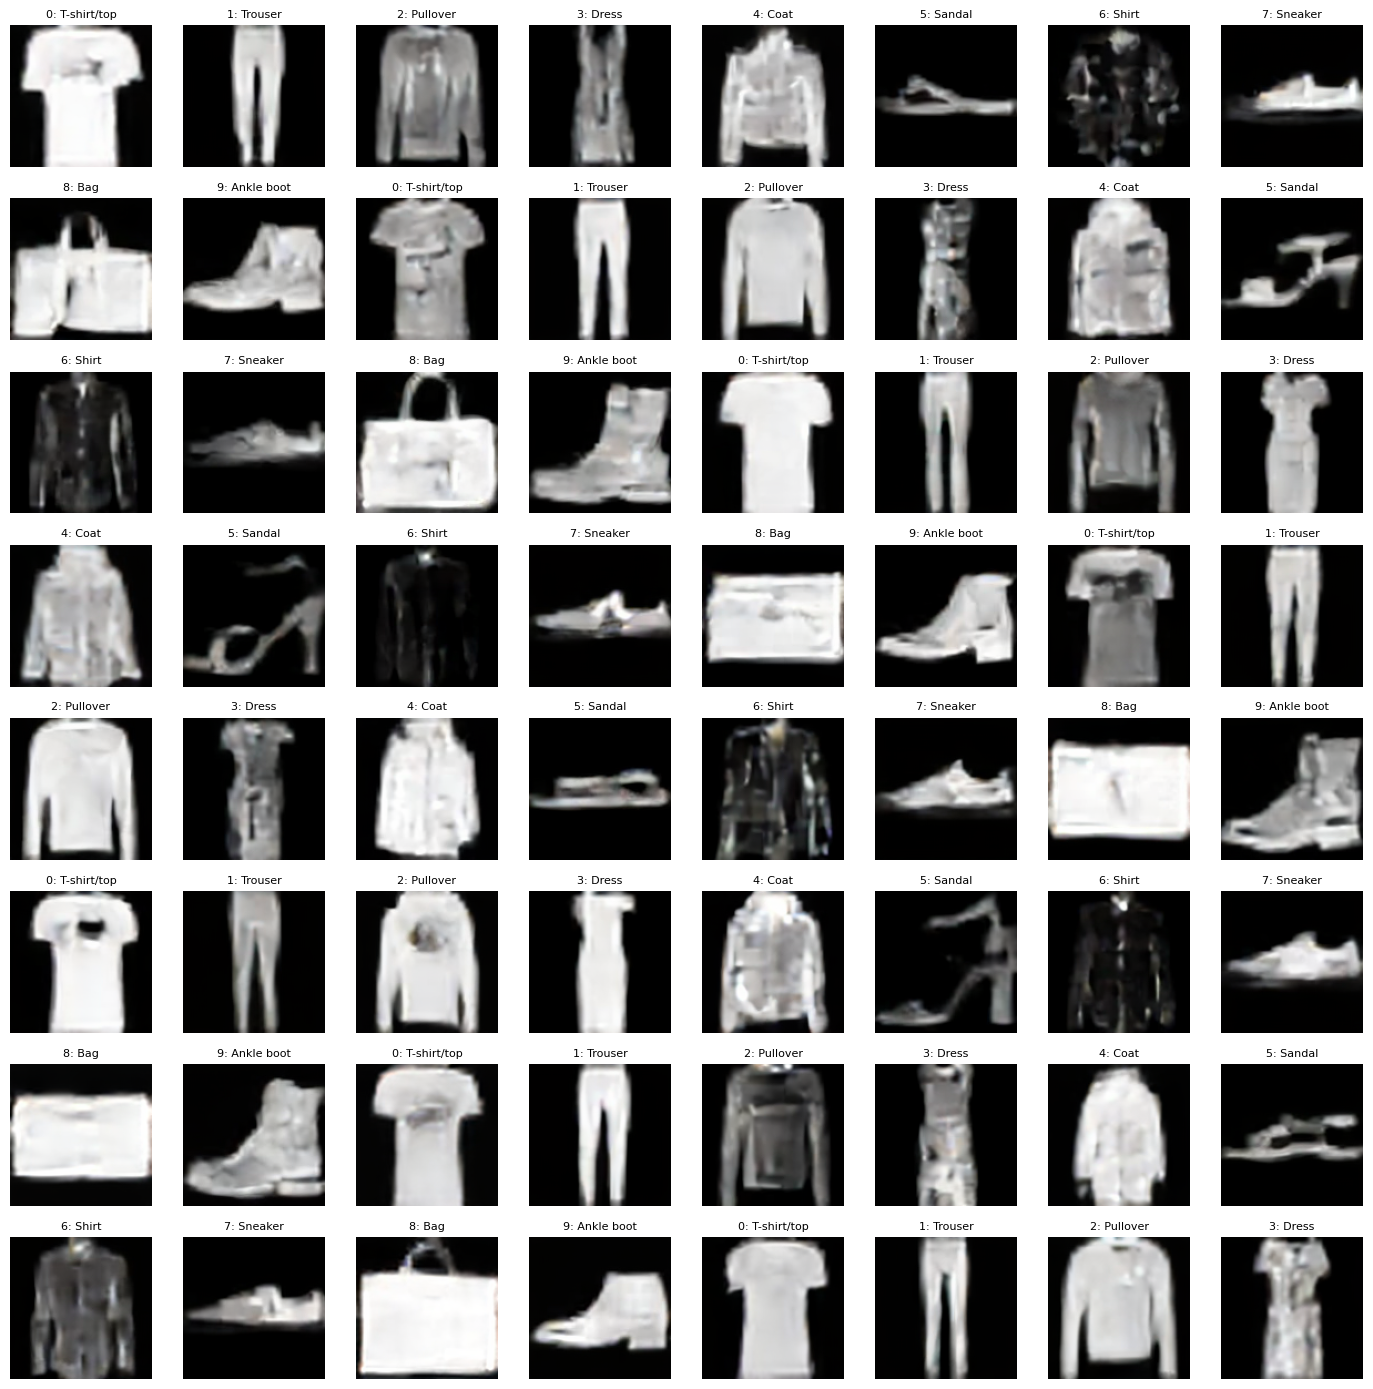

In [36]:
fig, axes = plt.subplots(
    8,
    8,
    figsize=(14, 14)
)

for index, axis in enumerate(axes.flat):
    image = denormalize(
        generated_images[index]
    ).permute(1, 2, 0)

    axis.imshow(image)
    axis.set_title(
        f"{sample_labels[index].item()}: "
        f"{CLASS_NAMES[sample_labels[index].item()]}",
        fontsize=8
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

## Step 12: Conditional and Unconditional Comparison

This section compares unconditional generation with class-conditional generation.

For unconditional generation, every label is replaced with the null label.

In [37]:
unconditional_labels = torch.full(
    (64,),
    NULL_LABEL,
    device=device,
    dtype=torch.long
)

unconditional_latents = sample_latents(
    model,
    unconditional_labels,
    guidance_scale=0.0
)

unconditional_images = decode_latents(
    unconditional_latents
).cpu()

Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

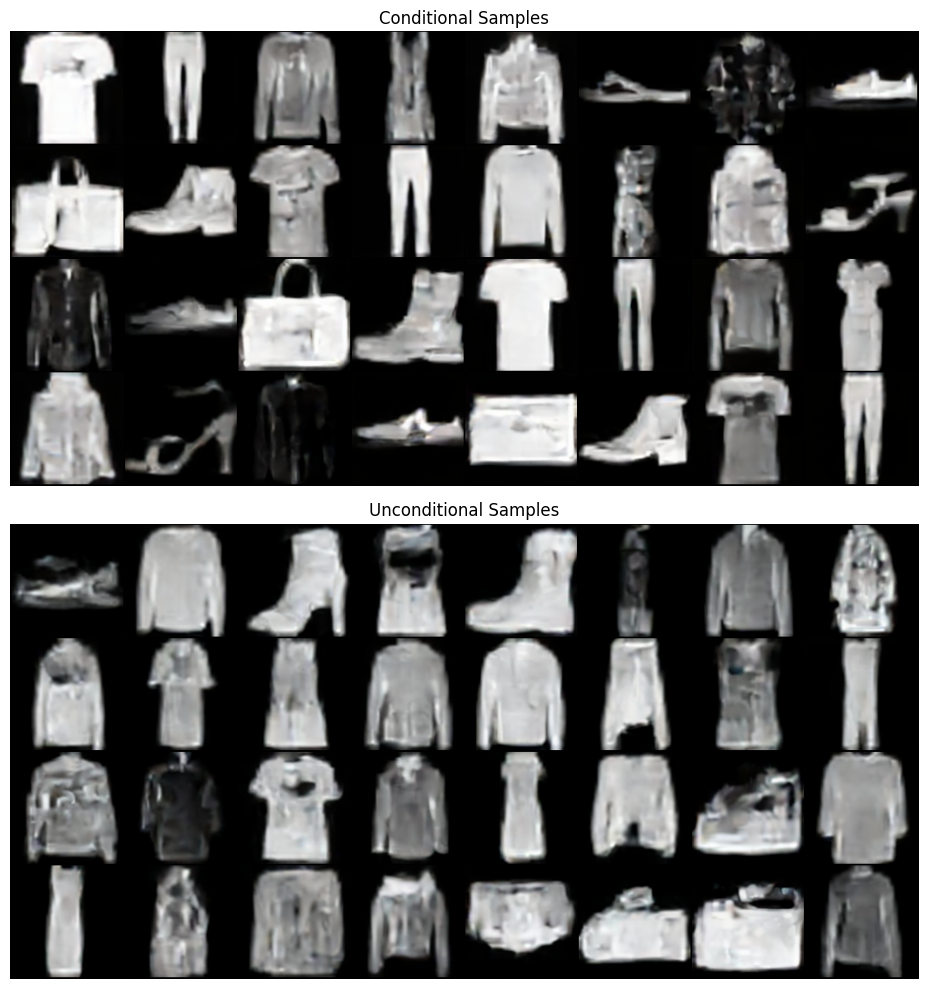

In [38]:
conditional_grid = make_grid(
    denormalize(generated_images[:32]),
    nrow=8,
    padding=2
)

unconditional_grid = make_grid(
    denormalize(unconditional_images[:32]),
    nrow=8,
    padding=2
)

plt.figure(figsize=(16, 10))

plt.subplot(2, 1, 1)
plt.imshow(conditional_grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Conditional Samples")

plt.subplot(2, 1, 2)
plt.imshow(unconditional_grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Unconditional Samples")

plt.tight_layout()
plt.show()

In [39]:
plt.savefig("filename.png", dpi=200, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [40]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "loss_history": loss_history,
        "seed": SEED,
        "guidance_scale": GUIDANCE_SCALE
    },
    "final_latent_diffusion_model.pt"
)

## Analysis

The VAE compresses each 128 × 128 FashionMNIST image into a 4 × 16 × 16 latent tensor. This reduces the spatial dimensionality while preserving enough information for image reconstruction.

The forward diffusion process gradually adds Gaussian noise to the latent representation. Early timesteps preserve recognizable clothing structure, while later timesteps produce nearly random latent representations.

The U-Net learns to predict the noise added at each timestep. Time embeddings allow the model to understand the current diffusion stage, while label embeddings provide class information.

Classifier-free guidance combines conditional and unconditional noise predictions. Increasing the guidance scale usually makes the generated class more recognizable, but very large values may reduce image diversity or produce artifacts.

The generated 64-image grid should contain examples corresponding to FashionMNIST classes 0 through 9:

- 0: T-shirt/top
- 1: Trouser
- 2: Pullover
- 3: Dress
- 4: Coat
- 5: Sandal
- 6: Shirt
- 7: Sneaker
- 8: Bag
- 9: Ankle boot

## Technical Difficulties and Best Practices

1. The Stable Diffusion VAE expects three-channel images, while FashionMNIST is grayscale. The images were therefore converted from one channel to three channels.

2. The VAE expects pixel values approximately in the range [-1, 1], so normalization was applied before encoding.

3. The images were resized to 128 × 128 so that the VAE latent representation became 16 × 16. This allowed self-attention to be applied at the required 16 × 16 resolution.

4. VAE latent representations were cached before diffusion training. This reduced training time because the frozen VAE did not need to encode every image during every epoch.

5. GPU memory was managed by using batches of 64 and storing cached latents in float16 format.

6. Classifier-free guidance requires both conditional and unconditional predictions. The null label was represented using class index 10.

7. Gradient clipping was used to reduce the chance of unstable training.

8. Model checkpoints were saved after every epoch so that training could be resumed if Colab disconnected.

9. A fixed random seed was used to improve reproducibility.

10. The generated images should be evaluated visually because FashionMNIST image quality and class consistency are especially important for this assignment.